## library

In [1]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from sklearn.datasets import fetch_california_housing

## load data

In [2]:
housing = fetch_california_housing(as_frame=True)
df = housing.frame
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41.0,6.984127,1.023810,322.0,2.555556,37.88,-122.23,4.526
1,8.3014,21.0,6.238137,0.971880,2401.0,2.109842,37.86,-122.22,3.585
2,7.2574,52.0,8.288136,1.073446,496.0,2.802260,37.85,-122.24,3.521
3,5.6431,52.0,5.817352,1.073059,558.0,2.547945,37.85,-122.25,3.413
4,3.8462,52.0,6.281853,1.081081,565.0,2.181467,37.85,-122.25,3.422


In [3]:
df.shape

(20640, 9)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  float64
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  float64
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(9)
memory usage: 1.4 MB


## check missing duplications

In [5]:
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

In [6]:
df.duplicated().sum()

np.int64(0)

## handling missing duplicates

In [7]:
df.drop_duplicates(inplace=True)

## data visual

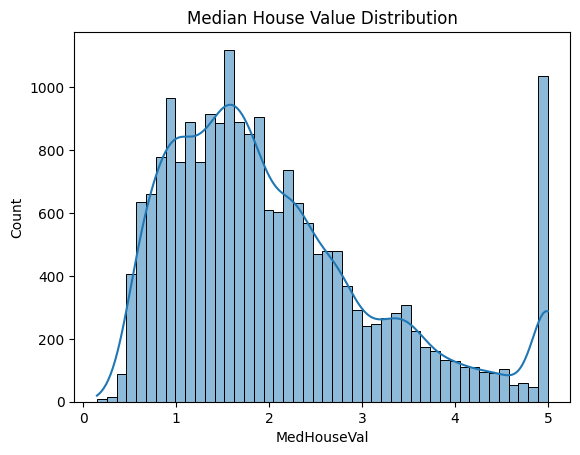

In [8]:
sns.histplot(df["MedHouseVal"], kde=True)
plt.title("Median House Value Distribution")
plt.show()

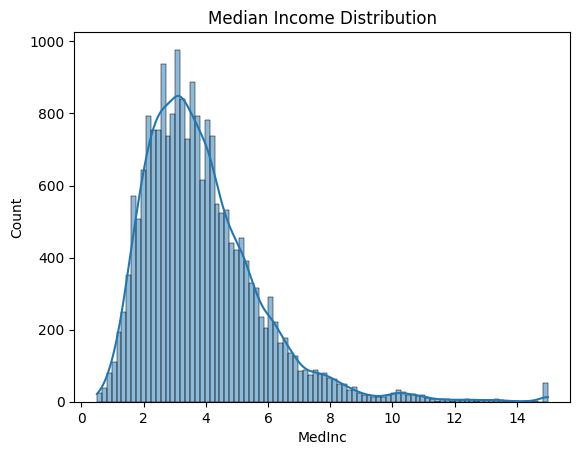

In [9]:
sns.histplot(df["MedInc"], kde=True)
plt.title("Median Income Distribution")
plt.show()

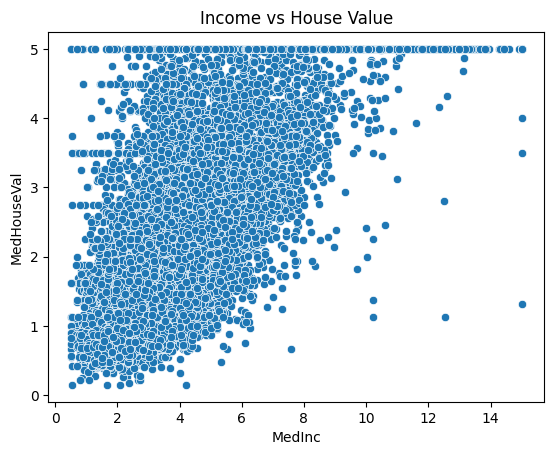

In [10]:
sns.scatterplot(x="MedInc", y="MedHouseVal", data=df)
plt.title("Income vs House Value")
plt.show()

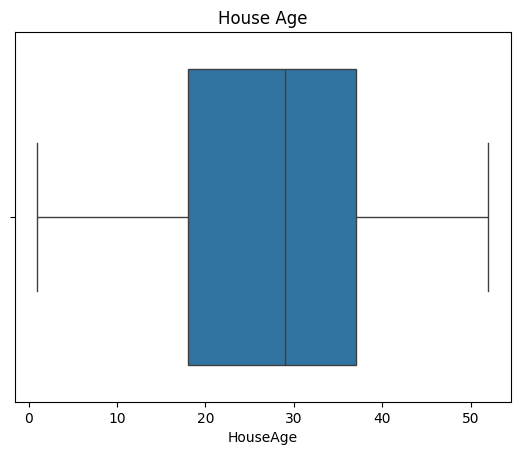

In [11]:
sns.boxplot(x="HouseAge", data=df)
plt.title("House Age")
plt.show()

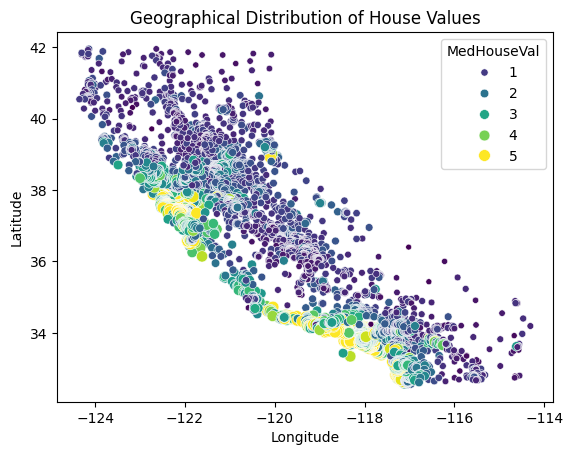

In [12]:
sns.scatterplot(x="Longitude", y="Latitude", hue="MedHouseVal", data=df, palette="viridis", size="MedHouseVal")
plt.title("Geographical Distribution of House Values")
plt.show()

## correlation analysis

In [13]:
corr = df.corr()
corr

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
MedInc,1.000000,-0.119034,0.326895,-0.050826,0.004834,0.018766,-0.079809,-0.015176,0.688075
HouseAge,-0.119034,1.000000,-0.153277,-0.060143,-0.296244,0.013191,0.011173,-0.108197,0.105623
AveRooms,0.326895,-0.153277,1.000000,0.777040,-0.072213,-0.004852,0.106389,-0.027540,0.151948
AveBedrms,-0.050826,-0.060143,0.777040,1.000000,-0.075265,-0.005708,0.065359,0.011529,-0.045637
Population,0.004834,-0.296244,-0.072213,-0.075265,1.000000,0.069863,-0.108785,0.099773,-0.024650
AveOccup,0.018766,0.013191,-0.004852,-0.005708,0.069863,1.000000,0.002366,0.002476,-0.023737
Latitude,-0.079809,0.011173,0.106389,0.065359,-0.108785,0.002366,1.000000,-0.924664,-0.144160
Longitude,-0.015176,-0.108197,-0.027540,0.011529,0.099773,0.002476,-0.924664,1.000000,-0.045967
MedHouseVal,0.688075,0.105623,0.151948,-0.045637,-0.024650,-0.023737,-0.144160,-0.045967,1.000000


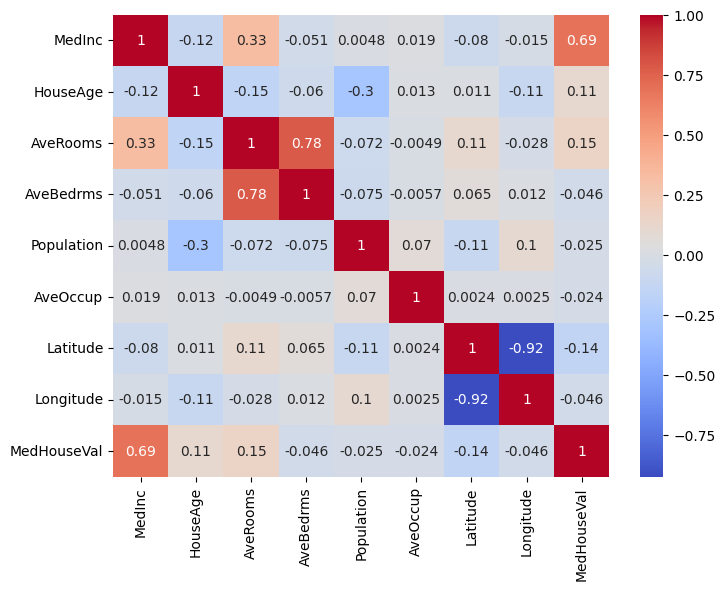

In [14]:
plt.figure(figsize=(8,6))
sns.heatmap(corr, annot=True, cmap="coolwarm")
plt.show()

## folium

In [ ]:
import folium

m = folium.Map(location=[36.7, -119.4], zoom_start=6)

sample = df.sample(300, random_state=42)

for _, row in sample.iterrows():
    folium.CircleMarker(
        location=[row["Latitude"], row["Longitude"]],
        radius=3,
        color="crimson" if row["MedHouseVal"] > df["MedHouseVal"].median() else "blue",
        fill=True,
        fill_opacity=0.6
    ).add_to(m)

m

In [16]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.100910,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.519159,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.121204,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.005525,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048860,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.100015,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


## data summary conclusion

- Median income is the strongest driver of median house value.
- House prices are noticeably higher near the coast, especially around the Bay Area and Los Angeles.
- No missing values or duplicates were found in this dataset.
- Latitude and longitude show clear geographical clustering of expensive areas on the map.